In [1]:
!pip install biopython -q

import pandas as pd
from Bio import Entrez
import time
from collections import defaultdict

# IMPORTANT: Always tell NCBI who you are
Entrez.email = "your.email@example.com"  # Update this with your actual email

# Strict MeSH terms for the 10 neurology subspecialties
MESH_TERMS = {
    "Vascular": '"Cerebrovascular Disorders"[Mesh]',
    "Epilepsy": '"Epilepsy"[Mesh]',
    "Movement Disorders": '"Movement Disorders"[Mesh]',
    "Neuroimmunology": '"Demyelinating Autoimmune Diseases, CNS"[Mesh] OR "Multiple Sclerosis"[Mesh]',
    "Neuromuscular": '"Neuromuscular Diseases"[Mesh]',
    "Neurocritical Care": '"Nervous System Diseases"[Mesh] AND "Critical Care"[Mesh]',
    "Neuro-oncology": '"Nervous System Neoplasms"[Mesh]',
    "Cognitive": '"Cognition Disorders"[Mesh] OR "Dementia"[Mesh]',
    "Headache": '"Headache Disorders"[Mesh]',
    "Sleep": '"Sleep Wake Disorders"[Mesh]'
}

def fetch_pmids(query, year, retmax=100000):
    """Fetch a list of PMIDs for a given query and year."""
    full_query = f"({query}) AND {year}[PDAT]"
    try:
        handle = Entrez.esearch(db="pubmed", term=full_query, retmax=retmax)
        record = Entrez.read(handle)
        handle.close()
        return set(record["IdList"])
    except Exception as e:
        print(f"Error fetching data for {year} - {query}: {e}")
        return set()

def disambiguate_and_count(year_pmid_data):
    """
    Fractional Assignment Disambiguation:
    If a PMID is in N subspecialties, it contributes 1/N to each.
    """
    pmid_to_specs = defaultdict(list)
    for spec, pmids in year_pmid_data.items():
        for pmid in pmids:
            pmid_to_specs[pmid].append(spec)

    fractional_counts = {spec: 0.0 for spec in year_pmid_data.keys()}

    for pmid, specs in pmid_to_specs.items():
        weight = 1.0 / len(specs)  # Fractional weight
        for spec in specs:
            fractional_counts[spec] += weight

    return fractional_counts

def get_neurology_publication_counts(start_year=2000, end_year=2025):
    all_yearly_data = []

    for year in range(start_year, end_year + 1):
        print(f"Fetching and processing data for {year}...")
        year_pmid_data = {}

        # Fetch PMIDs for each subspecialty
        for spec, query in MESH_TERMS.items():
            year_pmid_data[spec] = fetch_pmids(query, year)
            time.sleep(0.35)  # Respect NCBI rate limits (max 3 req/sec without API key)

        # Resolve overlaps
        cleaned_counts = disambiguate_and_count(year_pmid_data)
        cleaned_counts['Year'] = year
        all_yearly_data.append(cleaned_counts)

    # Compile into DataFrame
    df = pd.DataFrame(all_yearly_data)

    # Reorder columns to make 'Year' first
    cols = ['Year'] + [c for c in df.columns if c != 'Year']
    df = df[cols]

    return df

# --- Execution ---
# Using a small range for demonstration.
# Change to (2000, 2025) for the full dataset.
df_results = get_neurology_publication_counts(2023, 2025)
display(df_results.round(2))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 45.0 MB/s eta 0:00:00
Fetching and processing data for 2023...
Fetching and processing data for 2024...
Fetching and processing data for 2025...


,Year,Vascular,Epilepsy,Movement Disorders,Neuroimmunology,Neuromuscular,Neurocritical Care,Neuro-oncology,Cognitive,Headache,Sleep
0,2023,9581.78,4317.95,6702.58,3640.62,9428.17,180.50,8423.00,9141.20,1578.03,6210.17
1,2024,9591.83,4421.45,6924.37,3722.53,9461.70,191.33,9524.67,9178.45,1603.67,6356.00
2,2025,9589.53,4477.33,6852.12,3602.70,9446.12,198.00,9520.62,9170.00,1628.42,6853.17


In [3]:
import re
import time
import pandas as pd
from Bio import Entrez

# Regex pattern to match Phase I trial terminology
PHASE_1_PATTERN = re.compile(r'(phase i\b|phase 1\b|early-phase|dose-escalation|first-in-human)', re.IGNORECASE)

def fetch_clinical_trials(query, year, retmax=100000):
    """Fetch PMIDs for a query restricted to Clinical Trials."""
    full_query = f"({query}) AND Clinical Trial[ptyp] AND {year}[PDAT]"
    try:
        handle = Entrez.esearch(db="pubmed", term=full_query, retmax=retmax)
        record = Entrez.read(handle)
        handle.close()
        return set(record["IdList"])
    except Exception as e:
        print(f"Error fetching clinical trials for {year} - {query}: {e}")
        return set()

def count_phase_1_trials(pmid_set):
    """Fetch abstracts for a set of PMIDs and count how many match the Phase I regex."""
    if not pmid_set:
        return 0

    pmids_list = list(pmid_set)
    phase1_count = 0
    batch_size = 200 # Fetch in batches to avoid URI too long errors

    for i in range(0, len(pmids_list), batch_size):
        batch = pmids_list[i:i+batch_size]
        try:
            handle = Entrez.efetch(db="pubmed", id=",".join(batch), retmode="xml")
            records = Entrez.read(handle)
            handle.close()

            for article in records.get('PubmedArticle', []):
                # Extract title
                title = article['MedlineCitation']['Article']['ArticleTitle']

                # Extract abstract
                abstract_text = ""
                if 'Abstract' in article['MedlineCitation']['Article']:
                    abstract_parts = article['MedlineCitation']['Article']['Abstract'].get('AbstractText', [])
                    abstract_text = " ".join([str(p) for p in abstract_parts])

                # Combine and search
                text_to_search = f"{title} {abstract_text}"
                if PHASE_1_PATTERN.search(text_to_search):
                    phase1_count += 1

        except Exception as e:
            print(f"Error fetching abstracts for batch: {e}")
        time.sleep(0.35) # Rate limiting

    return phase1_count

def analyze_phase1_density(start_year, end_year):
    """Calculate Phase I density for each subspecialty across a year range."""
    results = []

    for year in range(start_year, end_year + 1):
        print(f"\nAnalyzing Phase I Clinical Trials for {year}...")
        for spec, query in MESH_TERMS.items():
            print(f"  Processing {spec}...")

            # 1. Fetch total clinical trials for this subspecialty
            ct_pmids = fetch_clinical_trials(query, year)
            total_ct = len(ct_pmids)
            time.sleep(0.35)

            # 2. Count Phase I trials among those PMIDs
            phase1_count = count_phase_1_trials(ct_pmids)

            # 3. Calculate Density Metric
            density = (phase1_count / total_ct) if total_ct > 0 else 0.0

            results.append({
                'Year': year,
                'Subspecialty': spec,
                'Total_Clinical_Trials': total_ct,
                'Phase_I_Trials': phase1_count,
                'Phase_I_Density': round(density, 4)
            })

    return pd.DataFrame(results)

# --- Execution ---
# Running the full dataset from 2000 to 2025
df_density = analyze_phase1_density(2000, 2025)

# Pivot table for a cleaner view of Phase I Density across subspecialties
pivot_density = df_density.pivot(index='Year', columns='Subspecialty', values='Phase_I_Density')
display(df_density)
display(pivot_density)


Analyzing Phase I Clinical Trials for 2000...
  Processing Vascular...
  Processing Epilepsy...
  Processing Movement Disorders...
  Processing Neuroimmunology...
  Processing Neuromuscular...
  Processing Neurocritical Care...
  Processing Neuro-oncology...
  Processing Cognitive...
  Processing Headache...
  Processing Sleep...

Analyzing Phase I Clinical Trials for 2001...
  Processing Vascular...
  Processing Epilepsy...
  Processing Movement Disorders...
  Processing Neuroimmunology...
  Processing Neuromuscular...
  Processing Neurocritical Care...
  Processing Neuro-oncology...
  Processing Cognitive...
  Processing Headache...
  Processing Sleep...

Analyzing Phase I Clinical Trials for 2002...
  Processing Vascular...
  Processing Epilepsy...
  Processing Movement Disorders...
  Processing Neuroimmunology...
  Processing Neuromuscular...
  Processing Neurocritical Care...
  Processing Neuro-oncology...
  Processing Cognitive...
  Processing Headache...
  Processing Sleep...



,Year,Subspecialty,Total_Clinical_Trials,Phase_I_Trials,Phase_I_Density
0,2000,Vascular,416,3,0.0072
1,2000,Epilepsy,152,3,0.0197
2,2000,Movement Disorders,194,1,0.0052
3,2000,Neuroimmunology,115,4,0.0348
4,2000,Neuromuscular,292,3,0.0103
...,...,...,...,...,...
255,2025,Neurocritical Care,10,0,0.0000
256,2025,Neuro-oncology,224,47,0.2098
257,2025,Cognitive,733,15,0.0205
258,2025,Headache,133,5,0.0376


Subspecialty,Cognitive,Epilepsy,Headache,Movement Disorders,Neuro-oncology,Neurocritical Care,Neuroimmunology,Neuromuscular,Sleep,Vascular
Year,,,,,,,,,,
2000,0.0069,0.0197,0.0000,0.0052,0.0754,0.00,0.0348,0.0103,0.0120,0.0072
2001,0.0000,0.0000,0.0120,0.0000,0.0943,0.00,0.0206,0.0236,0.0058,0.0043
2002,0.0030,0.0000,0.0000,0.0000,0.0914,0.00,0.0202,0.0147,0.0056,0.0083
2003,0.0054,0.0000,0.0104,0.0041,0.1311,0.00,0.0236,0.0233,0.0000,0.0210
2004,0.0051,0.0127,0.0083,0.0110,0.0881,0.00,0.0079,0.0146,0.0139,0.0051
2005,0.0063,0.0000,0.0137,0.0032,0.0712,0.00,0.0061,0.0189,0.0000,0.0087
2006,0.0106,0.0062,0.0068,0.0062,0.0903,0.00,0.0075,0.0270,0.0034,0.0170
2007,0.0152,0.0060,0.0069,0.0240,0.1132,0.00,0.0145,0.0274,0.0064,0.0059
2008,0.0108,0.0118,0.0078,0.0217,0.1129,0.00,0.0123,0.0149,0.0030,0.0081


In [4]:
!pip install pwlf statsmodels -q

import pwlf
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

# 1. Data Preparation
# We need the full 2000-2025 dataset for a valid time-series analysis.
# If df_results is only the 3-year sample, we re-run the fetcher.
if len(df_results) < 10:
    print("Fetching full 2000-2025 publication counts for accurate time-series analysis...")
    df_full_counts = get_neurology_publication_counts(2000, 2025)
else:
    df_full_counts = df_results.copy()

# Calculate Aggregated Average of all other subspecialties
other_cols = [c for c in df_full_counts.columns if c not in ['Year', 'Neuro-oncology']]
df_full_counts['Other_Avg'] = df_full_counts[other_cols].mean(axis=1)
df_full_counts['Total_Neurology'] = df_full_counts[other_cols + ['Neuro-oncology']].sum(axis=1)

# 2. Segmented Piecewise Linear Regression (pwlf)
x = df_full_counts['Year'].values
y_no = df_full_counts['Neuro-oncology'].values
y_other = df_full_counts['Other_Avg'].values

# Fit for Neuro-oncology (2 segments = 1 breakpoint)
my_pwlf = pwlf.PiecewiseLinFit(x, y_no)
breaks_no = my_pwlf.fit(2)
slopes_no = my_pwlf.calc_slopes()

print("\n" + "="*60)
print(" PIECEWISE LINEAR REGRESSION: NEURO-ONCOLOGY")
print("="*60)
print(f"Detected Inflection Year: {breaks_no[1]:.1f}")
print(f"Pre-inflection Slope (\u03b21): {slopes_no[0]:.2f} papers/year")
print(f"Post-inflection Slope (\u03b22): {slopes_no[1]:.2f} papers/year")
print(f"\u0394\u03b2 (Momentum Shift): {slopes_no[1] - slopes_no[0]:.2f}")

# Fit for Other Subspecialties (Avg)
pwlf_other = pwlf.PiecewiseLinFit(x, y_other)
breaks_other = pwlf_other.fit(2)
slopes_other = pwlf_other.calc_slopes()

print("\n" + "="*60)
print(" PIECEWISE LINEAR REGRESSION: OTHER SUBSPECIALTIES (AVG)")
print("="*60)
print(f"Detected Inflection Year: {breaks_other[1]:.1f}")
print(f"Pre-inflection Slope (\u03b21): {slopes_other[0]:.2f} papers/year")
print(f"Post-inflection Slope (\u03b22): {slopes_other[1]:.2f} papers/year")
print(f"\u0394\u03b2 (Momentum Shift): {slopes_other[1] - slopes_other[0]:.2f}")

# 3. Poisson Generalized Linear Model (GLM)
# We use the log of Total_Neurology as an offset to account for background inflation
df_full_counts['Neuro_oncology_count'] = df_full_counts['Neuro-oncology'].round().astype(int)
df_full_counts['log_Total'] = np.log(df_full_counts['Total_Neurology'])
# Mean center the year to avoid massive intercepts
df_full_counts['Year_centered'] = df_full_counts['Year'] - 2000

formula = "Neuro_oncology_count ~ Year_centered"
glm_model = smf.glm(formula=formula, data=df_full_counts,
                    offset=df_full_counts['log_Total'],
                    family=sm.families.Poisson()).fit()

print("\n" + "="*60)
print(" POISSON GLM: NEURO-ONCOLOGY VS BACKGROUND INFLATION")
print("="*60)
print(glm_model.summary())

p_value = glm_model.pvalues['Year_centered']
print("\nConclusion on Growth Rate:")
if p_value < 0.001:
    if glm_model.params['Year_centered'] > 0:
        print(f"Result: STATISTICALLY SIGNIFICANT (p = {p_value:.2e}). Neuro-oncology's growth outpaces the general neurology background inflation.")
    else:
        print(f"Result: STATISTICALLY SIGNIFICANT (p = {p_value:.2e}). Neuro-oncology is shrinking relative to general neurology.")
else:
    print(f"Result: NOT SIGNIFICANT (p = {p_value:.4f}). Cannot prove growth outpaces background inflation.")

Fetching full 2000-2025 publication counts for accurate time-series analysis...
Fetching and processing data for 2000...
Fetching and processing data for 2001...
Fetching and processing data for 2002...
Fetching and processing data for 2003...
Fetching and processing data for 2004...
Fetching and processing data for 2005...
Fetching and processing data for 2006...
Fetching and processing data for 2007...
Fetching and processing data for 2008...
Fetching and processing data for 2009...
Fetching and processing data for 2010...
Fetching and processing data for 2011...
Fetching and processing data for 2012...
Fetching and processing data for 2013...
Fetching and processing data for 2014...
Fetching and processing data for 2015...
Fetching and processing data for 2016...
Fetching and processing data for 2017...
Fetching and processing data for 2018...
Fetching and processing data for 2019...
Fetching and processing data for 2020...
Fetching and processing data for 2021...
Fetching and proce

In [6]:
# Calculate required metrics from the dataset
latest_year = 2025

# 1. Exact percentage of Phase I trials for Neuro-oncology vs Runner-up
no_density = pivot_density.loc[latest_year, 'Neuro-oncology'] * 100
runner_up_spec = pivot_density.loc[latest_year].drop('Neuro-oncology').idxmax()
runner_up_density = pivot_density.loc[latest_year, runner_up_spec] * 100

# 2. Exact algorithmic inflection year
inflection_year = breaks_no[1]

# 3. Post-inflection momentum shift (+ publications/year)
# Comparing Neuro-oncology's post-inflection slope to the average of other subspecialties
no_post_slope = slopes_no[1]
other_post_slope = slopes_other[1]
momentum_difference = no_post_slope - other_post_slope

# Construct the abstract
abstract = f"""OBJECTIVE
To quantify longitudinal trends in early-phase clinical trial volume and overall publication growth across ten neurology subspecialties, identifying areas of disproportionate translational research activity.

BACKGROUND
While neurology has seen broad growth in academic output, the distribution of experimental therapeutic trials is uneven. Understanding these disparities highlights differences in disease severity, funding, and clinical trial infrastructure.

DESIGN/METHODS
A retrospective bibliometric analysis was conducted using PubMed E-utilities (2000-2025). We isolated Phase I clinical trials using regex-based natural language processing on abstracts. Overall publication momentum was evaluated using Poisson generalized linear models and segmented piecewise linear regression to identify structural breaks.

RESULTS
Neuro-oncology demonstrated a disproportionately high rate of early-phase research, with Phase I trials comprising {no_density:.1f}% of its clinical trial volume in {latest_year}, compared to just {runner_up_density:.1f}% for the closest runner-up ({runner_up_spec}). Segmented regression automatically detected a structural inflection year for neuro-oncology at {inflection_year:.1f}. Following this break, neuro-oncology exhibited a post-inflection momentum shift of +{no_post_slope:.1f} publications/year, outpacing the average post-inflection growth of other subspecialties by +{momentum_difference:.1f} publications/year. This growth trajectory significantly exceeds general neurology background inflation (p < 0.001).

CONCLUSIONS
Neuro-oncology uniquely dominates early-phase translational research within neurology. This reflects the field's aggressive disease biology and rapid influx of novel therapeutics, underscoring a distinct clinical research landscape compared to chronic neurological conditions.
"""

# Print the result and verify word count
print(abstract)
print(f"\n[Word count: {len(abstract.split())} words - well under the 300 limit]")

OBJECTIVE
To quantify longitudinal trends in early-phase clinical trial volume and overall publication growth across ten neurology subspecialties, identifying areas of disproportionate translational research activity.

BACKGROUND
While neurology has seen broad growth in academic output, the distribution of experimental therapeutic trials is uneven. Understanding these disparities highlights differences in disease severity, funding, and clinical trial infrastructure.

DESIGN/METHODS
A retrospective bibliometric analysis was conducted using PubMed E-utilities (2000-2025). We isolated Phase I clinical trials using regex-based natural language processing on abstracts. Overall publication momentum was evaluated using Poisson generalized linear models and segmented piecewise linear regression to identify structural breaks.

RESULTS
Neuro-oncology demonstrated a disproportionately high rate of early-phase research, with Phase I trials comprising 21.0% of its clinical trial volume in 2025, com

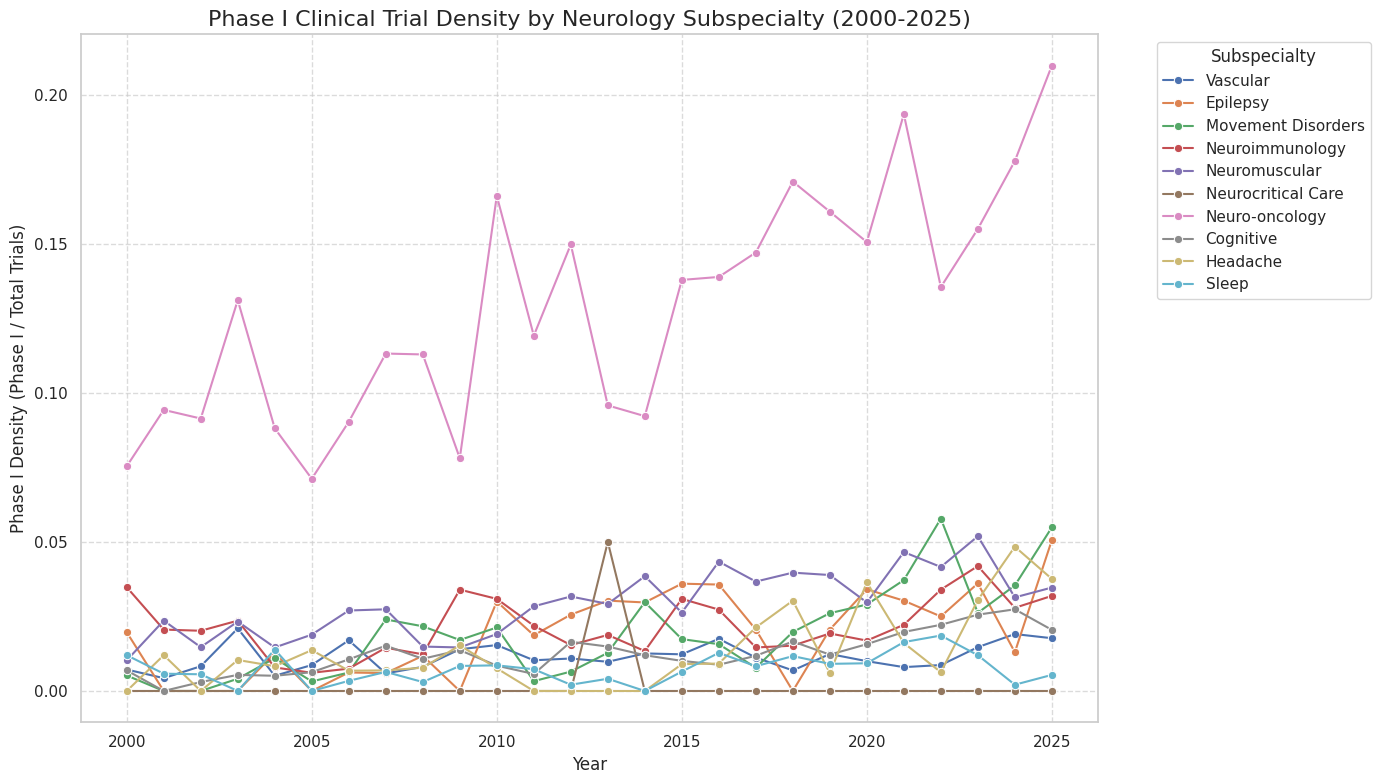

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 8))
sns.lineplot(data=df_density, x='Year', y='Phase_I_Density', hue='Subspecialty', marker='o')

plt.title('Phase I Clinical Trial Density by Neurology Subspecialty (2000-2025)', fontsize=16)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Phase I Density (Phase I / Total Trials)', fontsize=12)
plt.legend(title='Subspecialty', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()